# 01 · Data sources, the unified dataset and EDA

**Question:** after an information shock (an earnings release, or a ≥10% crash), does a US
stock keep moving the same way (**drift** — HW1 idea: momentum + PEAD) or snap back
(**reversal** — HW5 Q3: panic vs permanent damage)? Target: `growth_future_10d ≥ 1.02`
(enter at the next open, exit at the close 10 sessions later, ≥ +2% ≈ costs + profit).


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
events = store.read_table("events")
with store.connect() as con:
    sizes = {t: con.execute(f"select count(*) from {t}").fetchone()[0]
             for t in ["prices", "market", "macro", "filings", "eps_facts", "pageviews", "daily_panel", "events"]}
print({k: f"{v:,}" for k, v in sizes.items()}); print("total records:", f"{sum(sizes.values()):,}")

{'prices': '4,837,123', 'market': '50,226', 'macro': '21,565', 'filings': '2,021,569', 'eps_facts': '370,038', 'pageviews': '4,544,238', 'daily_panel': '4,835,791', 'events': '149,055'}
total records: 16,829,605


### Events per family and year

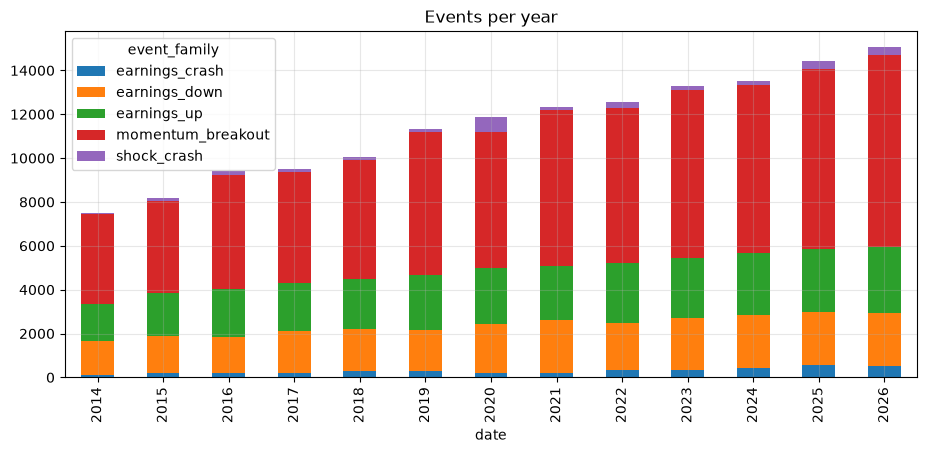

event_family,earnings_crash,earnings_down,earnings_up,momentum_breakout,shock_crash
date,,,,,
2014,102,1560,1680,4109,54
2015,180,1715,1966,4170,129
2016,217,1644,2153,5220,175
2017,216,1920,2154,5097,98
2018,272,1913,2306,5428,143
2019,280,1901,2472,6554,136
2020,200,2218,2560,6218,678
2021,199,2409,2473,7116,140
2022,321,2141,2773,7069,259


In [3]:
tab = events.pivot_table(index=events.date.dt.year, columns="event_family", values="ticker", aggfunc="size", fill_value=0)
tab.plot(kind="bar", stacked=True, title="Events per year"); plt.show(); tab

### Target: distribution of the 10-day forward return by family

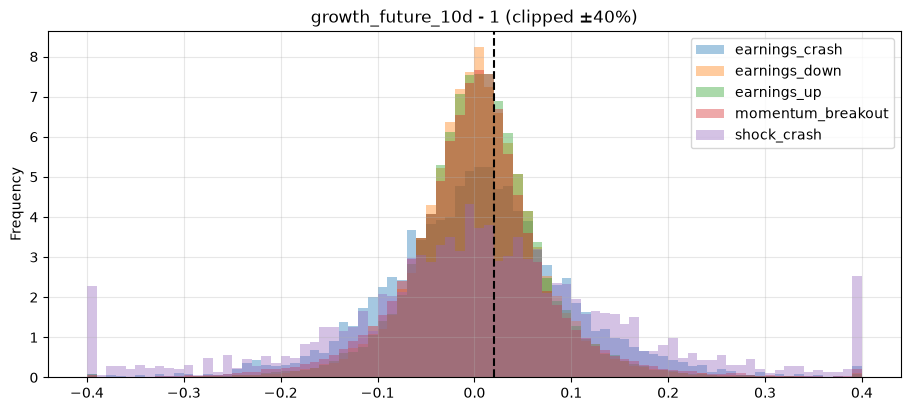

,n,base_rate,mean_10d,median_10d,mean_10d_vs_spy
event_family,,,,,
earnings_crash,3743,0.4138,0.0038,0.0032,-0.0017
earnings_down,26823,0.3764,0.0051,0.0038,-0.0012
earnings_up,31670,0.3823,0.0048,0.0043,-0.0013
momentum_breakout,82888,0.3614,0.0016,0.0018,-0.0017
shock_crash,2849,0.4468,0.0106,0.0050,0.0082


In [4]:
ml, feats = dataset.prepare(events)
known = ml[ml[dataset.TARGET].notna()]
fig, ax = plt.subplots()
for fam, g in known.groupby("event_family"):
    (g.growth_future_10d - 1).clip(-0.4, 0.4).plot(kind="hist", bins=80, alpha=0.4, density=True, ax=ax, label=fam)
ax.axvline(0.02, color="k", ls="--"); ax.legend(); ax.set_title("growth_future_10d - 1 (clipped ±40%)"); plt.show()
known.groupby("event_family").agg(n=("ticker", "size"), base_rate=(dataset.TARGET, "mean"),
    mean_10d=("growth_future_10d", lambda s: s.mean() - 1), median_10d=("growth_future_10d", lambda s: s.median() - 1),
    mean_10d_vs_spy=("growth_future_10d_vs_spy", lambda s: s.mean() - 1)).round(4)

### Event study: drift or reversal? (mean forward return vs SPY at 5/10/20 days)

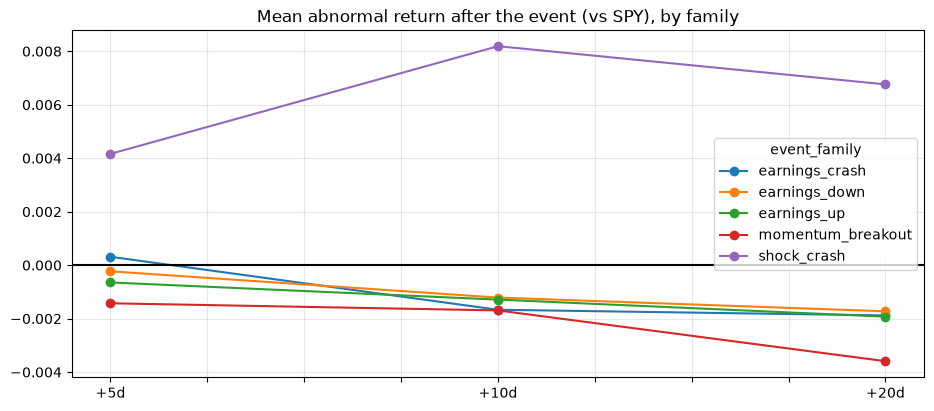

,+5d,+10d,+20d
event_family,,,
earnings_crash,0.0003,-0.0017,-0.0019
earnings_down,-0.0002,-0.0012,-0.0017
earnings_up,-0.0006,-0.0013,-0.0019
momentum_breakout,-0.0014,-0.0017,-0.0036
shock_crash,0.0042,0.0082,0.0068


In [5]:
es = known.groupby("event_family")[["growth_future_5d_vs_spy", "growth_future_10d_vs_spy", "growth_future_20d_vs_spy"]].mean() - 1
es.columns = ["+5d", "+10d", "+20d"]
es.T.plot(marker="o", title="Mean abnormal return after the event (vs SPY), by family"); plt.axhline(0, color="k"); plt.show()
es.round(4)

### EDGAR taxonomy test (HW5 Q3, stage 1): do crash causes have different base rates?

In [6]:
crash = known[known.event_family.isin(["shock_crash", "earnings_crash"])]
crash.groupby("edgar_category").agg(n=("ticker", "size"), bounce_rate=(dataset.TARGET, "mean"),
    mean_10d=("growth_future_10d", lambda s: s.mean() - 1), mean_mae=("mae_10d", "mean")).sort_values("n", ascending=False).round(3)

,n,bounce_rate,mean_10d,mean_mae
edgar_category,,,,
earnings,3907,0.414,0.004,-0.071
none,1976,0.459,0.011,-0.138
regfd_other_8k,317,0.420,0.014,-0.119
offering,154,0.390,-0.008,-0.102
mgmt_change,105,0.457,0.025,-0.089
deal,82,0.402,0.019,-0.094
restatement_auditor,29,0.379,-0.027,-0.138
bankruptcy_delisting,13,0.462,0.111,-0.130
impairment_restructuring,5,0.600,0.018,-0.043


### PEAD (HW1): post-earnings drift by surprise (SUE) and by blended momentum

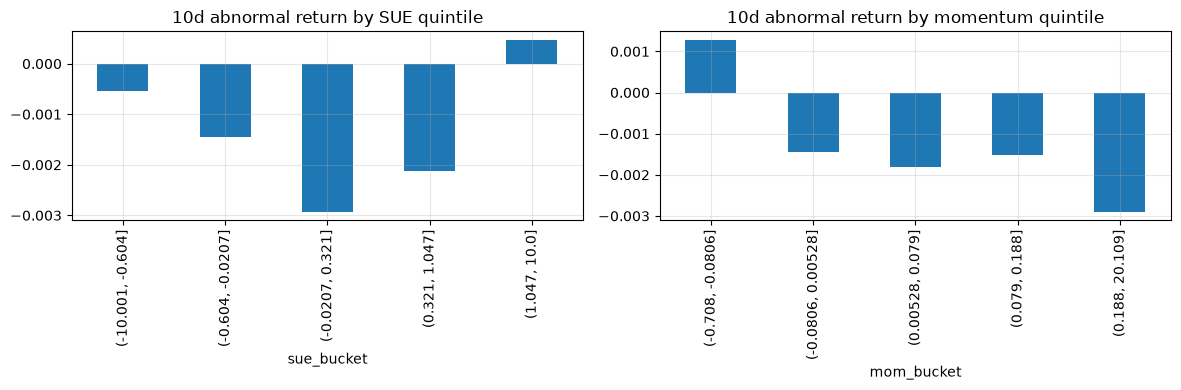

In [7]:
earn = known[known.event_family.str.startswith("earnings")].copy()
earn["sue_bucket"] = pd.qcut(earn["sue"], 5, duplicates="drop")
earn["mom_bucket"] = pd.qcut(earn["momentum_blend"], 5, duplicates="drop")
a = earn.groupby("sue_bucket", observed=True)["growth_future_10d_vs_spy"].mean() - 1
b = earn.groupby("mom_bucket", observed=True)["growth_future_10d_vs_spy"].mean() - 1
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
a.plot(kind="bar", ax=ax[0], title="10d abnormal return by SUE quintile")
b.plot(kind="bar", ax=ax[1], title="10d abnormal return by momentum quintile"); plt.tight_layout(); plt.show()

### Attention (Wikipedia pageviews) and market regime

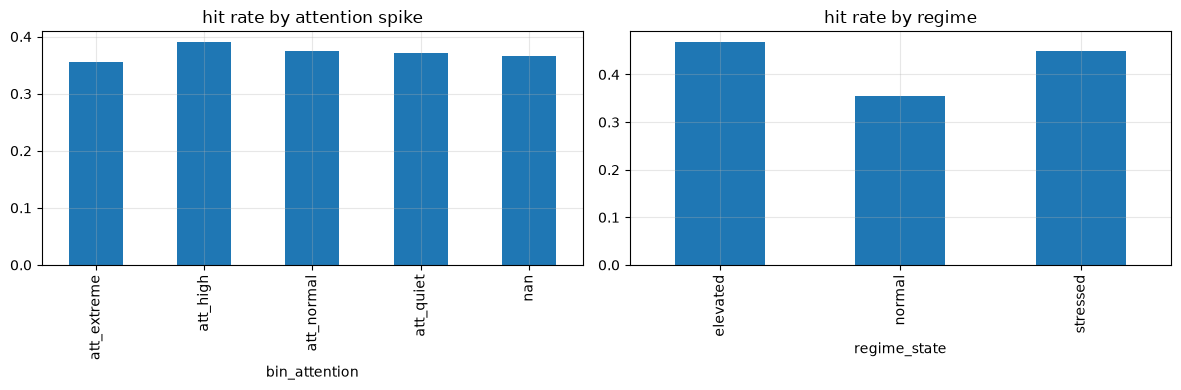

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
eda = dataset.add_engineered(events); eda = eda[eda[dataset.TARGET].notna()]   # bins before one-hot encoding
eda.groupby("bin_attention")[dataset.TARGET].mean().plot(kind="bar", ax=ax[0], title="hit rate by attention spike")
eda.groupby("regime_state")[dataset.TARGET].mean().plot(kind="bar", ax=ax[1], title="hit rate by regime"); plt.tight_layout(); plt.show()

### Correlation of features with the target

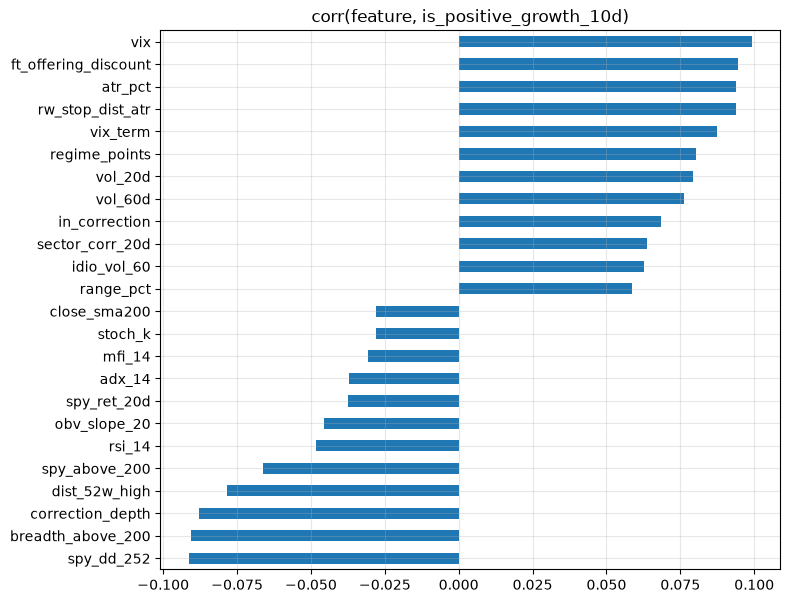

,corr_target,corr_growth
vix,0.0993,0.0674
ft_offering_discount,0.0947,0.1614
atr_pct,0.0939,0.0776
rw_stop_dist_atr,0.0939,0.0776
spy_dd_252,-0.0914,-0.0585
breadth_above_200,-0.0907,-0.0473
correction_depth,-0.0878,-0.0564
vix_term,0.0875,0.0329
regime_points,0.0802,0.0400
vol_20d,0.0794,0.0509


In [9]:
num = [c for c in dataset.numeric_features() if c in known]
corr = known[num].corrwith(known[dataset.TARGET]).dropna().sort_values()
corr_g = known[num].corrwith(known.growth_future_10d).dropna()
top = pd.concat([corr.head(12), corr.tail(12)])
top.plot(kind="barh", figsize=(8, 7), title="corr(feature, is_positive_growth_10d)"); plt.show()
pd.DataFrame({"corr_target": corr, "corr_growth": corr_g}).sort_values("corr_target", key=abs, ascending=False).head(20).round(4)

### Dummy correlations (one-hot sets)

In [10]:
dums = [c for c in feats if c not in num]
dc = known[dums].corrwith(known[dataset.TARGET]).dropna().sort_values(key=abs, ascending=False)
dc.head(20).round(4)

cs_rank_atr_pct          0.0669
cs_dm_atr_pct            0.0588
cs_rank_vol_20d          0.0584
bin_52w_near_high       -0.0571
cs_rank_idio_vol_60      0.0554
bin_momentum_mom_down    0.0527
cs_rank_beta_252         0.0520
cs_dm_idio_vol_60        0.0492
bin_reaction_flat       -0.0487
cs_dm_vol_20d            0.0485
cs_dm_beta_252           0.0475
cs_rank_range_pct        0.0467
cs_dm_dist_52w_high     -0.0442
bin_rsi_rsi_gt70        -0.0433
bin_52w_dd_gt50          0.0430
bin_52w_dd_30_50         0.0389
cs_rank_dist_52w_high   -0.0372
bin_momentum_mom_up     -0.0354
bin_reaction_up_3_10     0.0346
cs_dm_range_pct          0.0337
dtype: float64